<a href="https://colab.research.google.com/github/Swaathi-iyer/vehicle_detection_yolov8/blob/main/Autonomous_detection_yolov8_hypertune_xai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip uninstall -y torch torchvision torchaudio ultralytics
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install ultralytics

Found existing installation: torch 2.11.0+cu128
Uninstalling torch-2.11.0+cu128:
  Successfully uninstalled torch-2.11.0+cu128
Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.4/780.4 MB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 24.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 94.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 78.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 57.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 101.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

# Explainable YOLOv8 for Autonomous Driving in Indian Traffic
### Research Framework: Hyperparameter Tuning + Comparative Analysis + XAI
**Dataset:** IRUVD (Kaggle)
**Framework:** Ultralytics YOLOv8 + PyTorch + XAI

```
Section 0  → Environment Setup & Google Drive Mount
Section 1  → Dataset Verification & EDA
Section 2  → YOLOv8 Variant Comparison (n / s / m)
Section 3  → Hyperparameter Tuning
Section 4  → Evaluation & Metrics Comparison
Section 5  → XAI Integration (GradCAM, EigenCAM, GradCAM++)
Section 6  → XAI Analysis
Section 7  → Plots & Tables
```

---
## Section 0: Environment Setup

In [ ]:
!pip install -q kaggle
!pip install -q ultralytics
!pip install -q grad-cam==1.5.0
!pip install -q matplotlib seaborn pandas numpy Pillow tqdm
!pip install -q tabulate rich

import torch

print(f'\nPyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')

if torch.cuda.is_available():
    print(f'GPU             : {torch.cuda.get_device_name(0)}')
    print(f'VRAM            : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('WARNING: No GPU found. Go to Runtime > Change runtime type > T4 GPU')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 17.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done

PyTorch version : 2.5.1+cu121
CUDA available  : True
GPU             : Tesla T4
VRAM            : 15.6 GB


In [ ]:
import os

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d asfakali2/iruvd-dataset-for-automatic-vehicle-detection
!unzip -q iruvd-dataset-for-automatic-vehicle-detection.zip -d /content/IRUVD

DATASET_ROOT = '/content/IRUVD/JU_yolov5'

PROJECT_ROOT = '/content/YOLOv8_IRUVD_Research'

MODELS_DIR  = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR = os.path.join(PROJECT_ROOT, 'results')
PLOTS_DIR   = os.path.join(PROJECT_ROOT, 'plots')
XAI_DIR     = os.path.join(PROJECT_ROOT, 'xai_outputs')
LOGS_DIR    = os.path.join(PROJECT_ROOT, 'logs')

for d in [MODELS_DIR, RESULTS_DIR, PLOTS_DIR, XAI_DIR, LOGS_DIR]:
    os.makedirs(d, exist_ok=True)

print('Kaggle dataset connected successfully.')
print(f'Dataset root → {DATASET_ROOT}')
print(f'Project root → {PROJECT_ROOT}')

DATA_YAML = os.path.join(DATASET_ROOT, 'data.yaml')

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/asfakali2/iruvd-dataset-for-automatic-vehicle-detection
License(s): other
100% 2.55G/2.55G [00:38<00:00, 70.8MB/s]

Kaggle dataset connected successfully.
Dataset root → /content/IRUVD/JU_yolov5
Project root → /content/YOLOv8_IRUVD_Research


In [ ]:
from google.colab import files

print('Upload your kaggle.json file when prompted...')
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d asfakali2/iruvd-dataset-for-automatic-vehicle-detection
!unzip -q iruvd-dataset-for-automatic-vehicle-detection.zip -d /content/IRUVD

print('\nDataset downloaded. Folder contents:')
print(os.listdir('/content/IRUVD'))

Upload your kaggle.json file when prompted...


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/asfakali2/iruvd-dataset-for-automatic-vehicle-detection
License(s): other
iruvd-dataset-for-automatic-vehicle-detection.zip: Skipping, found more recently modified local copy (use --force to force download)
replace /content/IRUVD/JU_yolov5/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: A

Dataset downloaded. Folder contents:
['JU_yolov5']


In [ ]:
import os

DATASET_ROOT = '/content/IRUVD/JU_yolov5'
DATA_YAML    = os.path.join(DATASET_ROOT, 'data.yaml')


if not os.path.exists(DATASET_ROOT):

    for root, dirs, files_ in os.walk('/content/IRUVD'):
        if 'data.yaml' in files_:
            DATASET_ROOT = root
            DATA_YAML    = os.path.join(root, 'data.yaml')
            print(f'Auto-detected dataset at: {DATASET_ROOT}')
            break

print(f'DATASET_ROOT : {DATASET_ROOT}')
print(f'DATA_YAML    : {DATA_YAML}')
print(f'Contents     : {os.listdir(DATASET_ROOT)}')

DATASET_ROOT : /content/IRUVD/JU_yolov5
DATA_YAML    : /content/IRUVD/JU_yolov5/data.yaml
Contents     : ['valid', 'train', 'data.yaml']


In [ ]:
import yaml

with open(DATA_YAML) as f:
    yaml_cfg = yaml.safe_load(f)

print('Original data.yaml:')
print(yaml.dump(yaml_cfg))

train_split = 'train/images' if os.path.exists(
    os.path.join(DATASET_ROOT, 'train')) else 'images/train'
val_split   = 'valid/images' if os.path.exists(
    os.path.join(DATASET_ROOT, 'valid')) else 'val/images'

yaml_cfg['path']  = DATASET_ROOT
yaml_cfg['train'] = train_split
yaml_cfg['val']   = val_split

with open(DATA_YAML, 'w') as f:
    yaml.dump(yaml_cfg, f)

print('Patched data.yaml:')
print(yaml.dump(yaml_cfg))

VAL_SPLIT_NAME = 'valid' if os.path.exists(
    os.path.join(DATASET_ROOT, 'valid')) else 'val'
print(f'Val folder name: {VAL_SPLIT_NAME}')

Original data.yaml:
names:
- trak
- cyclist
- bike
- tempo
- car
- zeep
- toto
- e-rickshaw
- auto-rickshaw
- bus
- van
- cycle-rickshaw
- person
- taxi
nc: 14
train: ../train/images
val: ../valid/images

Patched data.yaml:
names:
- trak
- cyclist
- bike
- tempo
- car
- zeep
- toto
- e-rickshaw
- auto-rickshaw
- bus
- van
- cycle-rickshaw
- person
- taxi
nc: 14
path: /content/IRUVD/JU_yolov5
train: train/images
val: valid/images

Val folder name: valid


In [ ]:
import yaml

with open(DATA_YAML) as f:
    _cfg = yaml.safe_load(f)

CLASS_NAMES = _cfg['names']
NUM_CLASSES = len(CLASS_NAMES)
print(f'Classes ({NUM_CLASSES}): {CLASS_NAMES}')

Classes (14): ['trak', 'cyclist', 'bike', 'tempo', 'car', 'zeep', 'toto', 'e-rickshaw', 'auto-rickshaw', 'bus', 'van', 'cycle-rickshaw', 'person', 'taxi']


In [ ]:
import os, random, json, time, glob, shutil
import numpy as np
import torch
from pathlib import Path

SEED = 42

def set_seed(seed: int = SEED):
    """Fix all random seeds for full reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'

print(f'Config loaded | Device={DEVICE} | Classes={NUM_CLASSES}')
print(f'DATASET_ROOT  = {DATASET_ROOT}')
print(f'DATA_YAML     = {DATA_YAML}')
print(f'PROJECT_ROOT  = {PROJECT_ROOT}')

Config loaded | Device=cuda:0 | Classes=14
DATASET_ROOT  = /content/IRUVD/JU_yolov5
DATA_YAML     = /content/IRUVD/JU_yolov5/data.yaml
PROJECT_ROOT  = /content/YOLOv8_IRUVD_Research


---
## Section 1: Dataset Verification & Exploratory Data Analysis

In [ ]:
import glob
from pathlib import Path

def verify_dataset(root: str, val_name: str = 'valid') -> dict:
    """
    Verify YOLO-format dataset and return statistics.
    val_name: 'valid' or 'val' depending on dataset.
    """
    stats = {}
    for split in ['train', val_name]:
        img_dir = Path(root) / split / 'images'
        lbl_dir = Path(root) / split / 'labels'

        imgs = list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.png'))
        lbls = list(lbl_dir.glob('*.txt'))

        stats[split] = {
            'images': len(imgs),
            'labels': len(lbls),
            'img_dir_exists': img_dir.exists(),
            'lbl_dir_exists': lbl_dir.exists(),
        }
        print(f'  [{split:5s}] images={len(imgs):5d}  labels={len(lbls):5d}  '
              f'img_dir={img_dir.exists()}  lbl_dir={lbl_dir.exists()}')

    yaml_ok = Path(root, 'data.yaml').exists()
    print(f'  data.yaml present: {yaml_ok}')
    return stats

print('Verifying dataset structure ...')
ds_stats = verify_dataset(DATASET_ROOT, val_name=VAL_SPLIT_NAME)

Verifying dataset structure ...
  [train] images= 3200  labels= 3200  img_dir=True  lbl_dir=True
  [valid] images=  800  labels=  800  img_dir=True  lbl_dir=True
  data.yaml present: True


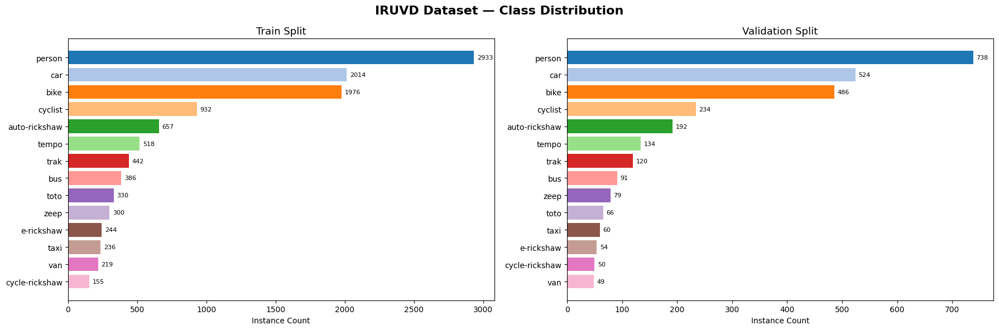

Class distribution plot saved.


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

def count_class_distribution(label_dir: str, class_names: list) -> Counter:
    """Parse all YOLO label files and count instances per class."""
    counter = Counter()
    for lbl_file in Path(label_dir).glob('*.txt'):
        with open(lbl_file) as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    cls_id = int(parts[0])
                    if 0 <= cls_id < len(class_names):
                        counter[class_names[cls_id]] += 1
    return counter

train_dist = count_class_distribution(
    os.path.join(DATASET_ROOT, 'train', 'labels'), CLASS_NAMES)
valid_dist = count_class_distribution(
    os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'labels'), CLASS_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('IRUVD Dataset — Class Distribution', fontsize=16, fontweight='bold')

for ax, dist, title in zip(axes,
                            [train_dist, valid_dist],
                            ['Train Split', 'Validation Split']):
    sorted_items = sorted(dist.items(), key=lambda x: -x[1])
    if sorted_items:
        names, counts = zip(*sorted_items)
        bars = ax.barh(names, counts, color=plt.cm.tab20(range(len(names))))
        ax.bar_label(bars, padding=4, fontsize=8)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('Instance Count')
    ax.invert_yaxis()

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'class_distribution.png'), dpi=150)
plt.show()
print('Class distribution plot saved.')

BBox size distribution (train):
  Small  (area < 0.01) :   6427  (56.7%)
  Medium (0.01-0.10)   :   3973  (35.0%)
  Large  (area >= 0.10):    942  (8.3%)


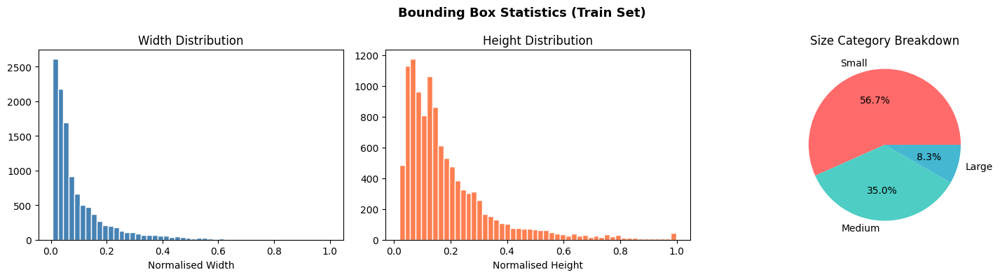

In [ ]:
import numpy as np

def analyze_bbox_sizes(label_dir: str):
    """
    YOLO format: [cls, cx, cy, w, h] normalised 0-1.
    Buckets: small < 0.01, medium 0.01-0.1, large >= 0.1
    """
    widths, heights, areas = [], [], []
    for lbl in Path(label_dir).glob('*.txt'):
        with open(lbl) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    w, h = float(parts[3]), float(parts[4])
                    widths.append(w)
                    heights.append(h)
                    areas.append(w * h)
    areas  = np.array(areas)
    small  = (areas < 0.01).sum()
    medium = ((areas >= 0.01) & (areas < 0.1)).sum()
    large  = (areas >= 0.1).sum()
    return widths, heights, areas, small, medium, large

ww, hh, aa, sm, md, lg = analyze_bbox_sizes(
    os.path.join(DATASET_ROOT, 'train', 'labels'))

if len(aa) > 0:
    print(f'BBox size distribution (train):')
    print(f'  Small  (area < 0.01) : {sm:6d}  ({100*sm/len(aa):.1f}%)')
    print(f'  Medium (0.01-0.10)   : {md:6d}  ({100*md/len(aa):.1f}%)')
    print(f'  Large  (area >= 0.10): {lg:6d}  ({100*lg/len(aa):.1f}%)')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle('Bounding Box Statistics (Train Set)', fontsize=13, fontweight='bold')

    axes[0].hist(ww, bins=50, color='steelblue', edgecolor='white')
    axes[0].set_title('Width Distribution')
    axes[0].set_xlabel('Normalised Width')

    axes[1].hist(hh, bins=50, color='coral', edgecolor='white')
    axes[1].set_title('Height Distribution')
    axes[1].set_xlabel('Normalised Height')

    axes[2].pie([sm, md, lg], labels=['Small', 'Medium', 'Large'],
                autopct='%1.1f%%', colors=['#FF6B6B', '#4ECDC4', '#45B7D1'])
    axes[2].set_title('Size Category Breakdown')

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, 'bbox_size_distribution.png'), dpi=150)
    plt.show()
else:
    print('No label files found — check DATASET_ROOT path.')

---
## Section 2: YOLOv8 Variant Comparison (n / s / m)

Three variants trained under **identical baseline hyperparameters**.

| Variant | Parameters | Notes |
|---------|-----------|-------|
| YOLOv8n | ~3.2 M  | Nano — fastest, best for edge |
| YOLOv8s | ~11.2 M | Small — balanced speed/accuracy |
| YOLOv8m | ~25.9 M | Medium — highest accuracy |

In [ ]:
from ultralytics import YOLO
import yaml, json, time

BASELINE_CFG = dict(
    data         = DATA_YAML,
    epochs       = 10,
    imgsz        = 640,
    batch        = 16,
    lr0          = 0.01,
    lrf          = 0.01,
    momentum     = 0.937,
    weight_decay = 0.0005,
    optimizer    = 'SGD',
    cos_lr       = True,
    seed         = SEED,
    device       = DEVICE,
    workers      = 4,
    verbose      = True,
    exist_ok     = True,
)

VARIANTS = ['yolov8n', 'yolov8s', 'yolov8m']

print('Baseline configuration:')
for k, v in BASELINE_CFG.items():
    print(f'  {k:20s} = {v}')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Baseline configuration:
  data                 = /content/IRUVD/JU_yolov5/data.yaml
  epochs               = 10
  imgsz                = 640
  batch                = 16
  lr0                  = 0.01
  lrf                  = 0.01
  momentum             = 0.937
  weight_decay         = 0.0005
  optimizer            = SGD
  cos_lr               = True
  seed                 = 42
  device               = cuda:0
  workers              = 4
  verbose              = True
  exist_ok             = True


In [ ]:
from ultralytics import YOLO
import torch

In [ ]:
variant_results = {}
VARIANTS = ['yolov8n', 'yolov8s', 'yolov8m']
for variant in VARIANTS:
    print(f'\n{"="*60}')
    print(f'  Training {variant.upper()} (baseline)')
    print(f'{"="*60}')

    model = YOLO(f'{variant}.pt')
    project_dir = os.path.join(PROJECT_ROOT, 'runs', 'baseline')

    t0 = time.time()
    model.train(
        **BASELINE_CFG,
        project = project_dir,
        name    = variant,
    )
    train_time = time.time() - t0


    metrics = model.val(data=DATA_YAML, device=DEVICE)


    sample_imgs = glob.glob(
        os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg'))[:50]
    t_inf = time.time()
    _ = model.predict(sample_imgs, device=DEVICE, verbose=False)
    fps = len(sample_imgs) / (time.time() - t_inf)

    variant_results[variant] = {
        'mAP50'    : float(metrics.box.map50),
        'mAP50_95' : float(metrics.box.map),
        'precision': float(metrics.box.mp),
        'recall'   : float(metrics.box.mr),
        'fps'      : round(fps, 1),
        'train_min': round(train_time / 60, 1),
        'model_path': os.path.join(project_dir, variant, 'weights', 'best.pt'),
    }

    best_src = os.path.join(project_dir, variant, 'weights', 'best.pt')
    best_dst = os.path.join(MODELS_DIR, f'{variant}_baseline_best.pt')
    if os.path.exists(best_src):
        shutil.copy2(best_src, best_dst)
        print(f'  Saved → {best_dst}')

    print(f'  {variant} | mAP50={variant_results[variant]["mAP50"]:.3f} '
          f'| FPS={fps:.1f}')

with open(os.path.join(RESULTS_DIR, 'baseline_variant_results.json'), 'w') as f:
    json.dump(variant_results, f, indent=2)
print('\nAll variant results saved.')


  Training YOLOV8N (baseline)
Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/IRUVD/JU_yolov5/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, o

---
## Section 3: Hyperparameter Tuning

Base model: **YOLOv8s** (best speed/accuracy trade-off).  

| HP | Why it matters for Indian Traffic |
|----|-----------------------------------|
| `lr0` | Too high → diverges on cluttered scenes |
| `imgsz` | Larger → better small object recall (cyclists, pedestrians) |
| `batch` | Larger → more stable gradients for rare classes |
| `weight_decay` | Prevents overfitting to dominant classes (car) |
| `mosaic` | Critical for multi-class Indian traffic diversity |
| `optimizer` | AdamW converges faster than SGD on imbalanced data |
| `degrees/shear` | Indian traffic has unusual vehicle orientations |

In [ ]:
HP_EXPERIMENTS = {

    'lr_low': {
        'lr0': 0.001,
        'lrf': 0.1
    },

    'lr_high': {
        'lr0': 0.05,
        'lrf': 0.01
    },
}

In [ ]:
hp_results = {}

BASE_WEIGHTS = '/content/best_s.pt'

print(f'Using baseline weights: {BASE_WEIGHTS}')

for exp_name, hp_override in HP_EXPERIMENTS.items():
    print(f'\n{"─"*55}')
    print(f'  Experiment : {exp_name}')
    print(f'  Overrides  : {hp_override}')
    print(f'{"─"*55}')

    run_cfg = {**BASELINE_CFG, **hp_override}
    if exp_name != 'tuned_best':
        run_cfg['epochs'] = 30

    model = YOLO(BASE_WEIGHTS)

    t0 = time.time()
    model.train(
        **run_cfg,
        project = os.path.join(PROJECT_ROOT, 'runs', 'hp_tuning'),
        name    = exp_name,
    )
    elapsed = time.time() - t0

    metrics = model.val(data=DATA_YAML, device=DEVICE)

    sample_imgs = glob.glob(
        os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg'))[:50]
    t_inf = time.time()
    _ = model.predict(sample_imgs, device=DEVICE, verbose=False)
    fps = len(sample_imgs) / (time.time() - t_inf)

    hp_results[exp_name] = {
        'mAP50'    : float(metrics.box.map50),
        'mAP50_95' : float(metrics.box.map),
        'precision': float(metrics.box.mp),
        'recall'   : float(metrics.box.mr),
        'fps'      : round(fps, 1),
        'train_min': round(elapsed / 60, 1),
        'config'   : hp_override,
    }

    best_src = os.path.join(
      PROJECT_ROOT, 'runs', 'hp_tuning', exp_name, 'weights', 'best.pt')
    if os.path.exists(best_src):
        shutil.copy2(best_src,
                     os.path.join(MODELS_DIR, f'{exp_name}_best.pt'))

    print(f'  mAP50={hp_results[exp_name]["mAP50"]:.3f} '
          f'mAP50-95={hp_results[exp_name]["mAP50_95"]:.3f} '
          f'FPS={fps:.1f}')

with open(os.path.join(RESULTS_DIR, 'hp_tuning_results.json'), 'w') as f:
    json.dump(hp_results, f, indent=2)
print('\nHP tuning results saved.')

Using baseline weights: /content/best_s.pt

───────────────────────────────────────────────────────
  Experiment : lr_low
  Overrides  : {'lr0': 0.001, 'lrf': 0.1}
───────────────────────────────────────────────────────
Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/IRUVD/JU_yolov5/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, 

In [ ]:
HP_EXPERIMENTS = {

    'lr_adamw': {
        'lr0': 0.001,
        'optimizer': 'AdamW',
        'lrf': 0.1
    },

    'imgsz_512': {
        'imgsz': 512
    },
}

In [ ]:
hp_results = {}

BASE_WEIGHTS = '/content/best_s.pt'

print(f'Using baseline weights: {BASE_WEIGHTS}')

for exp_name, hp_override in HP_EXPERIMENTS.items():
    print(f'\n{"─"*55}')
    print(f'  Experiment : {exp_name}')
    print(f'  Overrides  : {hp_override}')
    print(f'{"─"*55}')

    run_cfg = {**BASELINE_CFG, **hp_override}
    if exp_name != 'tuned_best':
        run_cfg['epochs'] = 30

    model = YOLO(BASE_WEIGHTS)

    t0 = time.time()
    model.train(
        **run_cfg,
        project = os.path.join(PROJECT_ROOT, 'runs', 'hp_tuning'),
        name    = exp_name,
    )
    elapsed = time.time() - t0

    metrics = model.val(data=DATA_YAML, device=DEVICE)

    sample_imgs = glob.glob(
        os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg'))[:50]
    t_inf = time.time()
    _ = model.predict(sample_imgs, device=DEVICE, verbose=False)
    fps = len(sample_imgs) / (time.time() - t_inf)

    hp_results[exp_name] = {
        'mAP50'    : float(metrics.box.map50),
        'mAP50_95' : float(metrics.box.map),
        'precision': float(metrics.box.mp),
        'recall'   : float(metrics.box.mr),
        'fps'      : round(fps, 1),
        'train_min': round(elapsed / 60, 1),
        'config'   : hp_override,
    }

    best_src = os.path.join(
      PROJECT_ROOT, 'runs', 'hp_tuning', exp_name, 'weights', 'best.pt')
    if os.path.exists(best_src):
        shutil.copy2(best_src,
                     os.path.join(MODELS_DIR, f'{exp_name}_best.pt'))

    print(f'  mAP50={hp_results[exp_name]["mAP50"]:.3f} '
          f'mAP50-95={hp_results[exp_name]["mAP50_95"]:.3f} '
          f'FPS={fps:.1f}')

with open(os.path.join(RESULTS_DIR, 'hp_tuning_results.json'), 'w') as f:
    json.dump(hp_results, f, indent=2)
print('\nHP tuning results saved.')

Using baseline weights: /content/best_s.pt

───────────────────────────────────────────────────────
  Experiment : lr_adamw
  Overrides  : {'lr0': 0.001, 'optimizer': 'AdamW', 'lrf': 0.1}
───────────────────────────────────────────────────────
Ultralytics 8.4.52 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/IRUVD/JU_yolov5/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=Non

In [ ]:
HP_EXPERIMENTS = {

    'imgsz_768': {
        'imgsz': 768,
        'batch': 8
    },
}

In [ ]:
hp_results = {}

BASE_WEIGHTS = '/content/best_s.pt'

print(f'Using baseline weights: {BASE_WEIGHTS}')

for exp_name, hp_override in HP_EXPERIMENTS.items():
    print(f'\n{"─"*55}')
    print(f'  Experiment : {exp_name}')
    print(f'  Overrides  : {hp_override}')
    print(f'{"─"*55}')

    run_cfg = {**BASELINE_CFG, **hp_override}
    if exp_name != 'tuned_best':
        run_cfg['epochs'] = 30

    model = YOLO(BASE_WEIGHTS)

    t0 = time.time()
    model.train(
        **run_cfg,
        project = os.path.join(PROJECT_ROOT, 'runs', 'hp_tuning'),
        name    = exp_name,
    )
    elapsed = time.time() - t0

    metrics = model.val(data=DATA_YAML, device=DEVICE)

    sample_imgs = glob.glob(
        os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg'))[:50]
    t_inf = time.time()
    _ = model.predict(sample_imgs, device=DEVICE, verbose=False)
    fps = len(sample_imgs) / (time.time() - t_inf)

    hp_results[exp_name] = {
        'mAP50'    : float(metrics.box.map50),
        'mAP50_95' : float(metrics.box.map),
        'precision': float(metrics.box.mp),
        'recall'   : float(metrics.box.mr),
        'fps'      : round(fps, 1),
        'train_min': round(elapsed / 60, 1),
        'config'   : hp_override,
    }

    best_src = os.path.join(
      PROJECT_ROOT, 'runs', 'hp_tuning', exp_name, 'weights', 'best.pt')
    if os.path.exists(best_src):
        shutil.copy2(best_src,
                     os.path.join(MODELS_DIR, f'{exp_name}_best.pt'))

    print(f'  mAP50={hp_results[exp_name]["mAP50"]:.3f} '
          f'mAP50-95={hp_results[exp_name]["mAP50_95"]:.3f} '
          f'FPS={fps:.1f}')

with open(os.path.join(RESULTS_DIR, 'hp_tuning_results.json'), 'w') as f:
    json.dump(hp_results, f, indent=2)
print('\nHP tuning results saved.')

Using baseline weights: /content/best_s.pt

───────────────────────────────────────────────────────
  Experiment : imgsz_768
  Overrides  : {'imgsz': 768, 'batch': 8}
───────────────────────────────────────────────────────
Ultralytics 8.4.52 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/IRUVD/JU_yolov5/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01,

In [ ]:
HP_EXPERIMENTS = {

    'batch_8': {
        'batch': 8
    },
}

In [ ]:
hp_results = {}

BASE_WEIGHTS = '/content/best_s.pt'

print(f'Using baseline weights: {BASE_WEIGHTS}')

for exp_name, hp_override in HP_EXPERIMENTS.items():
    print(f'\n{"─"*55}')
    print(f'  Experiment : {exp_name}')
    print(f'  Overrides  : {hp_override}')
    print(f'{"─"*55}')

    run_cfg = {**BASELINE_CFG, **hp_override}
    if exp_name != 'tuned_best':
        run_cfg['epochs'] = 30

    model = YOLO(BASE_WEIGHTS)

    t0 = time.time()
    model.train(
        **run_cfg,
        project = os.path.join(PROJECT_ROOT, 'runs', 'hp_tuning'),
        name    = exp_name,
    )
    elapsed = time.time() - t0

    metrics = model.val(data=DATA_YAML, device=DEVICE)

    sample_imgs = glob.glob(
        os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg'))[:50]
    t_inf = time.time()
    _ = model.predict(sample_imgs, device=DEVICE, verbose=False)
    fps = len(sample_imgs) / (time.time() - t_inf)

    hp_results[exp_name] = {
        'mAP50'    : float(metrics.box.map50),
        'mAP50_95' : float(metrics.box.map),
        'precision': float(metrics.box.mp),
        'recall'   : float(metrics.box.mr),
        'fps'      : round(fps, 1),
        'train_min': round(elapsed / 60, 1),
        'config'   : hp_override,
    }

    best_src = os.path.join(
      PROJECT_ROOT, 'runs', 'hp_tuning', exp_name, 'weights', 'best.pt')
    if os.path.exists(best_src):
        shutil.copy2(best_src,
                     os.path.join(MODELS_DIR, f'{exp_name}_best.pt'))

    print(f'  mAP50={hp_results[exp_name]["mAP50"]:.3f} '
          f'mAP50-95={hp_results[exp_name]["mAP50_95"]:.3f} '
          f'FPS={fps:.1f}')

with open(os.path.join(RESULTS_DIR, 'hp_tuning_results.json'), 'w') as f:
    json.dump(hp_results, f, indent=2)
print('\nHP tuning results saved.')

Using baseline weights: /content/best_s.pt

───────────────────────────────────────────────────────
  Experiment : batch_8
  Overrides  : {'batch': 8}
───────────────────────────────────────────────────────
Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/IRUVD/JU_yolov5/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, m

In [ ]:
HP_EXPERIMENTS = {

    'batch_32': {
        'batch': 32
    },

    'wd_low': {
        'weight_decay': 0.0001
    },
}

In [ ]:
hp_results = {}

BASE_WEIGHTS = '/content/best_s.pt'

print(f'Using baseline weights: {BASE_WEIGHTS}')

for exp_name, hp_override in HP_EXPERIMENTS.items():
    print(f'\n{"─"*55}')
    print(f'  Experiment : {exp_name}')
    print(f'  Overrides  : {hp_override}')
    print(f'{"─"*55}')

    run_cfg = {**BASELINE_CFG, **hp_override}
    if exp_name != 'tuned_best':
        run_cfg['epochs'] = 30

    model = YOLO(BASE_WEIGHTS)

    t0 = time.time()
    model.train(
        **run_cfg,
        project = os.path.join(PROJECT_ROOT, 'runs', 'hp_tuning'),
        name    = exp_name,
    )
    elapsed = time.time() - t0

    metrics = model.val(data=DATA_YAML, device=DEVICE)

    sample_imgs = glob.glob(
        os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg'))[:50]
    t_inf = time.time()
    _ = model.predict(sample_imgs, device=DEVICE, verbose=False)
    fps = len(sample_imgs) / (time.time() - t_inf)

    hp_results[exp_name] = {
        'mAP50'    : float(metrics.box.map50),
        'mAP50_95' : float(metrics.box.map),
        'precision': float(metrics.box.mp),
        'recall'   : float(metrics.box.mr),
        'fps'      : round(fps, 1),
        'train_min': round(elapsed / 60, 1),
        'config'   : hp_override,
    }

    best_src = os.path.join(
      PROJECT_ROOT, 'runs', 'hp_tuning', exp_name, 'weights', 'best.pt')
    if os.path.exists(best_src):
        shutil.copy2(best_src,
                     os.path.join(MODELS_DIR, f'{exp_name}_best.pt'))

    print(f'  mAP50={hp_results[exp_name]["mAP50"]:.3f} '
          f'mAP50-95={hp_results[exp_name]["mAP50_95"]:.3f} '
          f'FPS={fps:.1f}')

with open(os.path.join(RESULTS_DIR, 'hp_tuning_results.json'), 'w') as f:
    json.dump(hp_results, f, indent=2)
print('\nHP tuning results saved.')

Using baseline weights: /content/best_s.pt

───────────────────────────────────────────────────────
  Experiment : batch_32
  Overrides  : {'batch': 32}
───────────────────────────────────────────────────────
Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/IRUVD/JU_yolov5/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4

In [ ]:
HP_EXPERIMENTS = {

    'wd_high': {
        'weight_decay': 0.001
    },

    'aug_light': {
        'mosaic': 0.5,
        'degrees': 0.0,
        'shear': 0.0,
        'fliplr': 0.5,
    },
}

In [ ]:
hp_results = {}

BASE_WEIGHTS = '/content/best_s.pt'

print(f'Using baseline weights: {BASE_WEIGHTS}')

for exp_name, hp_override in HP_EXPERIMENTS.items():
    print(f'\n{"─"*55}')
    print(f'  Experiment : {exp_name}')
    print(f'  Overrides  : {hp_override}')
    print(f'{"─"*55}')

    run_cfg = {**BASELINE_CFG, **hp_override}
    if exp_name != 'tuned_best':
        run_cfg['epochs'] = 30

    model = YOLO(BASE_WEIGHTS)

    t0 = time.time()
    model.train(
        **run_cfg,
        project = os.path.join(PROJECT_ROOT, 'runs', 'hp_tuning'),
        name    = exp_name,
    )
    elapsed = time.time() - t0

    metrics = model.val(data=DATA_YAML, device=DEVICE)

    sample_imgs = glob.glob(
        os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg'))[:50]
    t_inf = time.time()
    _ = model.predict(sample_imgs, device=DEVICE, verbose=False)
    fps = len(sample_imgs) / (time.time() - t_inf)

    hp_results[exp_name] = {
        'mAP50'    : float(metrics.box.map50),
        'mAP50_95' : float(metrics.box.map),
        'precision': float(metrics.box.mp),
        'recall'   : float(metrics.box.mr),
        'fps'      : round(fps, 1),
        'train_min': round(elapsed / 60, 1),
        'config'   : hp_override,
    }

    best_src = os.path.join(
      PROJECT_ROOT, 'runs', 'hp_tuning', exp_name, 'weights', 'best.pt')
    if os.path.exists(best_src):
        shutil.copy2(best_src,
                     os.path.join(MODELS_DIR, f'{exp_name}_best.pt'))

    print(f'  mAP50={hp_results[exp_name]["mAP50"]:.3f} '
          f'mAP50-95={hp_results[exp_name]["mAP50_95"]:.3f} '
          f'FPS={fps:.1f}')

with open(os.path.join(RESULTS_DIR, 'hp_tuning_results.json'), 'w') as f:
    json.dump(hp_results, f, indent=2)
print('\nHP tuning results saved.')

Using baseline weights: /content/best_s.pt

───────────────────────────────────────────────────────
  Experiment : wd_high
  Overrides  : {'weight_decay': 0.001}
───────────────────────────────────────────────────────
Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/IRUVD/JU_yolov5/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mas

In [ ]:
HP_EXPERIMENTS = {

    'aug_heavy': {
        'mosaic': 1.0,
        'degrees': 15.0,
        'shear': 5.0,
        'scale': 0.6,
        'fliplr': 0.5,
        'hsv_h': 0.02,
        'hsv_s': 0.8,
        'hsv_v': 0.5,
        'mixup': 0.1,
        'copy_paste': 0.1,
    },
    'tuned_best': {
    'lr0': 0.001,
    'lrf': 0.1,
    'optimizer': 'AdamW',

    'imgsz': 768,
    'batch': 8,

    'weight_decay': 0.0005,

    'epochs': 30,

    'mosaic': 1.0,
    'degrees': 10.0,
    'shear': 3.0,
    'scale': 0.5,

    'mixup': 0.05,
    'copy_paste': 0.0,

    'cos_lr': True,
    'warmup_epochs': 3,
}

}

In [ ]:
hp_results = {}

BASE_WEIGHTS = '/content/best_s.pt'

print(f'Using baseline weights: {BASE_WEIGHTS}')

for exp_name, hp_override in HP_EXPERIMENTS.items():
    print(f'\n{"─"*55}')
    print(f'  Experiment : {exp_name}')
    print(f'  Overrides  : {hp_override}')
    print(f'{"─"*55}')

    run_cfg = {**BASELINE_CFG, **hp_override}
    if exp_name != 'tuned_best':
        run_cfg['epochs'] = 30

    model = YOLO(BASE_WEIGHTS)

    t0 = time.time()
    model.train(
        **run_cfg,
        project = os.path.join(PROJECT_ROOT, 'runs', 'hp_tuning'),
        name    = exp_name,
    )
    elapsed = time.time() - t0

    metrics = model.val(data=DATA_YAML, device=DEVICE)

    sample_imgs = glob.glob(
        os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg'))[:50]
    t_inf = time.time()
    _ = model.predict(sample_imgs, device=DEVICE, verbose=False)
    fps = len(sample_imgs) / (time.time() - t_inf)

    hp_results[exp_name] = {
        'mAP50'    : float(metrics.box.map50),
        'mAP50_95' : float(metrics.box.map),
        'precision': float(metrics.box.mp),
        'recall'   : float(metrics.box.mr),
        'fps'      : round(fps, 1),
        'train_min': round(elapsed / 60, 1),
        'config'   : hp_override,
    }

    best_src = os.path.join(
      PROJECT_ROOT, 'runs', 'hp_tuning', exp_name, 'weights', 'best.pt')
    if os.path.exists(best_src):
        shutil.copy2(best_src,
                     os.path.join(MODELS_DIR, f'{exp_name}_best.pt'))

    print(f'  mAP50={hp_results[exp_name]["mAP50"]:.3f} '
          f'mAP50-95={hp_results[exp_name]["mAP50_95"]:.3f} '
          f'FPS={fps:.1f}')

with open(os.path.join(RESULTS_DIR, 'hp_tuning_results.json'), 'w') as f:
    json.dump(hp_results, f, indent=2)
print('\nHP tuning results saved.')

Using baseline weights: /content/best_s.pt

───────────────────────────────────────────────────────
  Experiment : aug_heavy
  Overrides  : {'mosaic': 1.0, 'degrees': 15.0, 'shear': 5.0, 'scale': 0.6, 'fliplr': 0.5, 'hsv_h': 0.02, 'hsv_s': 0.8, 'hsv_v': 0.5, 'mixup': 0.1, 'copy_paste': 0.1}
───────────────────────────────────────────────────────
Ultralytics 8.4.54 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/IRUVD/JU_yolov5/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False,

In [ ]:
import shutil
import os

os.makedirs(MODELS_DIR, exist_ok=True)

model_files = [
    'best_m.pt',
    'best_s.pt',
    'best_n.pt',
    'tuned_best_best.pt'
]

for model_name in model_files:
    shutil.copy(
        f'/content/{model_name}',
        os.path.join(MODELS_DIR, model_name)
    )

print('All models copied successfully.')

All models copied successfully.


---
## Section 4: Evaluation & Metrics Comparison

In [ ]:
from ultralytics import YOLO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd
from tabulate import tabulate

try:
    with open(os.path.join(RESULTS_DIR, 'baseline_variant_results.json')) as f:
        variant_results = json.load(f)
    with open(os.path.join(RESULTS_DIR, 'hp_tuning_results.json')) as f:
        hp_results = json.load(f)
    print('Loaded saved results.')
except FileNotFoundError:
    print('Results not found — run Sections 2 & 3 first.')

def evaluate_model_per_class(
        weights_path: str, data_yaml: str, device: str, label: str) -> pd.DataFrame:
    """Run validation and return per-class AP50 as a DataFrame."""
    model   = YOLO(weights_path)
    metrics = model.val(data=data_yaml, device=device, verbose=False)
    per_class = {
        CLASS_NAMES[i]: float(ap)
        for i, ap in zip(metrics.box.ap_class_index, metrics.box.ap50)
        if i < len(CLASS_NAMES)
    }
    return pd.DataFrame.from_dict(per_class, orient='index', columns=[label])

eval_models = {
    'YOLOv8n (baseline)': os.path.join(MODELS_DIR, 'yolov8n_baseline_best.pt'),
    'YOLOv8s (baseline)': os.path.join(MODELS_DIR, 'yolov8s_baseline_best.pt'),
    'YOLOv8m (baseline)': os.path.join(MODELS_DIR, 'yolov8m_baseline_best.pt'),
    'YOLOv8s (tuned)'   : os.path.join(MODELS_DIR, 'tuned_best_best.pt'),
}

pc_dfs = []
for label, wpath in eval_models.items():
    if os.path.exists(wpath):
        pc_dfs.append(evaluate_model_per_class(wpath, DATA_YAML, DEVICE, label))
    else:
        print(f'Weights not found: {wpath}')

if pc_dfs:
    per_class_df = pd.concat(pc_dfs, axis=1)
    per_class_df.loc['MEAN'] = per_class_df.mean()
    per_class_df.to_csv(os.path.join(RESULTS_DIR, 'per_class_ap50.csv'))
    print('\nPer-Class AP@0.5 Comparison')
    print(tabulate(per_class_df.round(3), headers='keys', tablefmt='github'))

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Results not found — run Sections 2 & 3 first.
Weights not found: /content/YOLOv8_IRUVD_Research/models/yolov8n_baseline_best.pt
Weights not found: /content/YOLOv8_IRUVD_Research/models/yolov8s_baseline_best.pt
Weights not found: /content/YOLOv8_IRUVD_Research/models/yolov8m_baseline_best.pt
Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,131,002 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3051.8±801.9 MB/s, size: 699.0 KB)
val: Scanning /content/IRUVD/JU_yolov5/valid/labels... 800 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 2.1Kit/s 0.4s
val: New cache 

In [ ]:
variant_results = {
    'yolov8n': {
        'model_path': os.path.join(MODELS_DIR, 'best_n.pt')
    },
    'yolov8s': {
        'model_path': os.path.join(MODELS_DIR, 'best_s.pt')
    },
    'yolov8m': {
        'model_path': os.path.join(MODELS_DIR, 'best_m.pt')
    },
}

hp_results = {
    'tuned_best': {
        'model_path': os.path.join(MODELS_DIR, 'tuned_best_best.pt')
    }
}

In [ ]:
from ultralytics import YOLO
import pandas as pd
import time
import glob
from tabulate import tabulate

eval_models = {
    'YOLOv8n Baseline': os.path.join(MODELS_DIR, 'best_n.pt'),
    'YOLOv8s Baseline': os.path.join(MODELS_DIR, 'best_s.pt'),
    'YOLOv8m Baseline': os.path.join(MODELS_DIR, 'best_m.pt'),
    'YOLOv8s Tuned'  : os.path.join(MODELS_DIR, 'tuned_best_best.pt'),
}

rows = []

sample_imgs = glob.glob(
    os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images', '*.jpg')
)[:50]

for model_name, weights_path in eval_models.items():

    print(f'\nEvaluating {model_name}')

    model = YOLO(weights_path)

    metrics = model.val(
        data=DATA_YAML,
        device=DEVICE,
        verbose=False
    )

    t0 = time.time()

    _ = model.predict(
        sample_imgs,
        device=DEVICE,
        verbose=False
    )

    fps = len(sample_imgs) / (time.time() - t0)

    rows.append({
        'Model'      : model_name,
        'Precision'  : round(float(metrics.box.mp), 3),
        'Recall'     : round(float(metrics.box.mr), 3),
        'mAP50'      : round(float(metrics.box.map50), 3),
        'mAP50-95'   : round(float(metrics.box.map), 3),
        'FPS'        : round(fps, 1),
    })

summary_df = pd.DataFrame(rows)

summary_df.to_csv(
    os.path.join(RESULTS_DIR, 'model_comparison_summary.csv'),
    index=False
)

print('\nModel Comparison Summary')
print(tabulate(summary_df, headers='keys',
               tablefmt='github', showindex=False))


Evaluating YOLOv8n Baseline
Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,008,378 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2873.5±464.7 MB/s, size: 613.1 KB)
val: Scanning /content/IRUVD/JU_yolov5/valid/labels.cache... 800 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 239.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 3.6it/s 13.9s
                   all        800       2877      0.865      0.776      0.857      0.721
Speed: 1.4ms preprocess, 3.0ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/val-2

Evaluating YOLOv8s Baseline
Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,131,002 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, rea

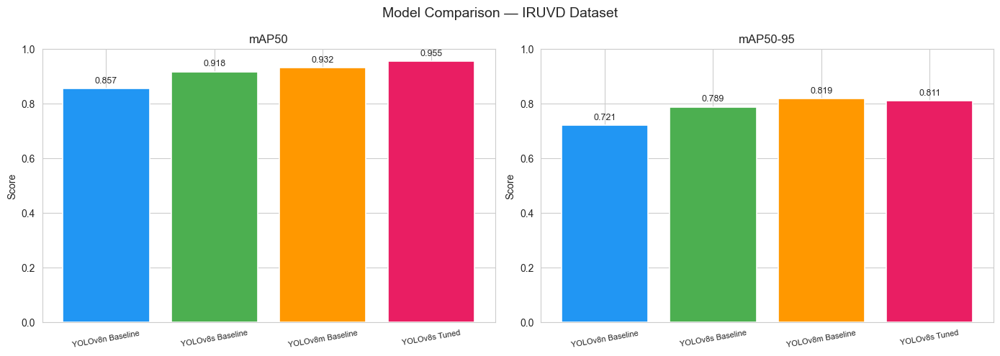

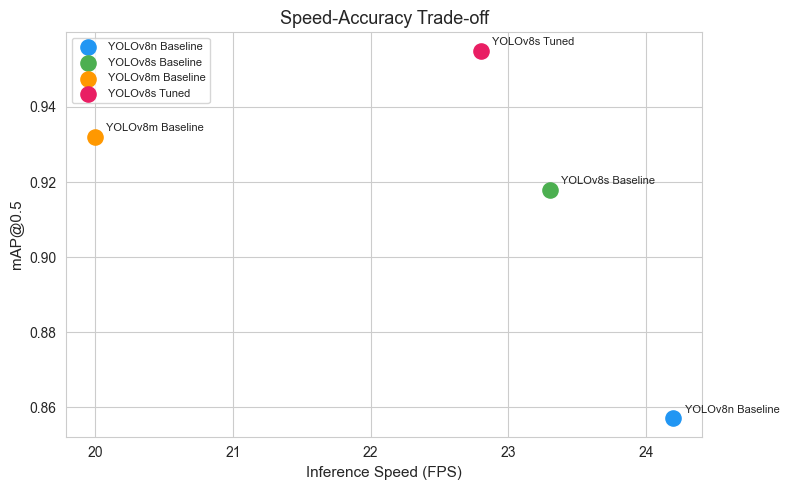

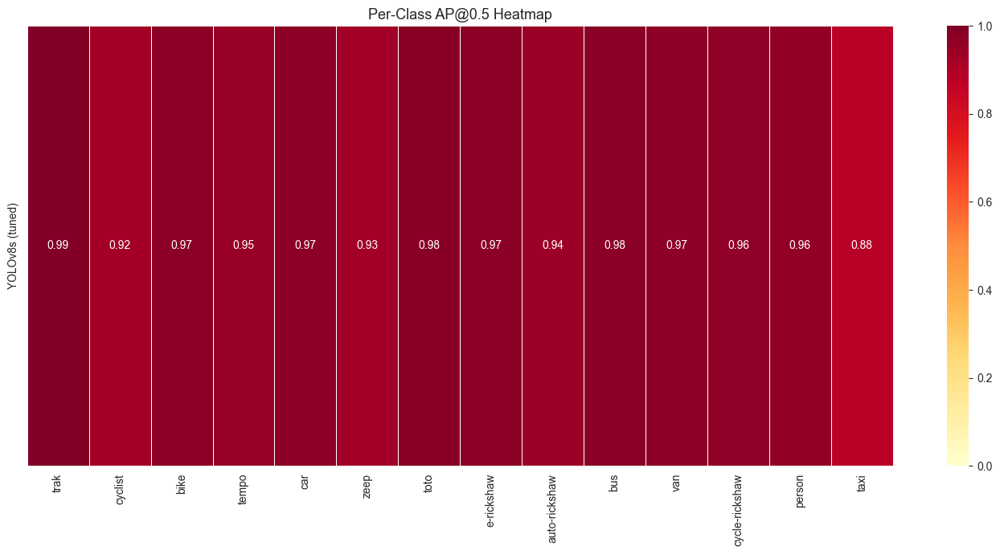

All comparison plots saved.


In [ ]:
import seaborn as sns

sns.set_style('whitegrid')

COLORS = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fig.suptitle(
    'Model Comparison — IRUVD Dataset',
    fontsize=14,
    fontweight='bold'
)

for ax, metric in zip(axes, ['mAP50', 'mAP50-95']):

    bars = ax.bar(
        summary_df['Model'],
        summary_df[metric],
        color=COLORS[:len(summary_df)],
        edgecolor='white',
        linewidth=1.2
    )

    ax.set_title(metric, fontsize=12)
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)

    ax.bar_label(
        bars,
        fmt='%.3f',
        padding=3,
        fontsize=9
    )

    ax.tick_params(axis='x', labelsize=8, rotation=10)

plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS_DIR, 'map_comparison.png'),
    dpi=150
)

plt.show()

fig, ax = plt.subplots(figsize=(8, 5))

for i, row in summary_df.iterrows():

    ax.scatter(
        row['FPS'],
        row['mAP50'],
        s=120,
        color=COLORS[i % len(COLORS)],
        label=row['Model'],
        zorder=5
    )

    ax.annotate(
        row['Model'],
        (row['FPS'], row['mAP50']),
        textcoords='offset points',
        xytext=(8, 4),
        fontsize=8
    )

ax.set_xlabel('Inference Speed (FPS)', fontsize=11)

ax.set_ylabel('mAP@0.5', fontsize=11)

ax.set_title(
    'Speed-Accuracy Trade-off',
    fontsize=13,
    fontweight='bold'
)

ax.legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS_DIR, 'speed_accuracy_tradeoff.png'),
    dpi=150
)

plt.show()

if 'per_class_df' in dir() and not per_class_df.empty:

    fig, ax = plt.subplots(figsize=(14, 7))

    data_heat = per_class_df.drop('MEAN', errors='ignore').T

    sns.heatmap(
        data_heat,
        annot=True,
        fmt='.2f',
        cmap='YlOrRd',
        linewidths=0.5,
        ax=ax,
        vmin=0,
        vmax=1
    )

    ax.set_title(
        'Per-Class AP@0.5 Heatmap',
        fontsize=13,
        fontweight='bold'
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(PLOTS_DIR, 'per_class_heatmap.png'),
        dpi=150
    )

    plt.show()

print('All comparison plots saved.')

---
## Section 5: XAI Integration — GradCAM, EigenCAM, GradCAM++

| Method | Mechanism | Best For |
|--------|-----------|----------|
| **GradCAM** | Gradient of target w.r.t. feature maps | Quick global attention |
| **GradCAM++** | Weighted positive gradients | Multiple instances |
| **EigenCAM** | PCA of feature maps (no gradient) | Stable, fast |

In [ ]:
import cv2
from PIL import Image
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, EigenCAM
from pytorch_grad_cam.utils.image import show_cam_on_image


class YOLOv8GradCAMWrapper(torch.nn.Module):
    """
    Wraps YOLOv8 for pytorch-grad-cam compatibility.
    Returns summed confidence scores as a scalar gradient signal.
    """
    def __init__(self, model):
        super().__init__()
        self.model = model.model

    def forward(self, x):
        preds = self.model(x)
        if isinstance(preds, (list, tuple)):
            return preds[0].view(preds[0].size(0), -1).sum(dim=1, keepdim=True)
        return preds.view(preds.size(0), -1).sum(dim=1, keepdim=True)


def get_target_layer(yolo_model):
    """
    Target the last C2f block in the YOLOv8 neck.
    This layer has the best mix of semantic richness + spatial resolution.
    """
    return [yolo_model.model.model[-3]]


def preprocess_image_for_cam(img_path: str, imgsz: int = 640):
    """Load and preprocess image. Returns (tensor, rgb_float)."""
    img_bgr  = cv2.imread(img_path)
    img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resz = cv2.resize(img_rgb, (imgsz, imgsz))
    rgb_float = img_resz.astype(np.float32) / 255.0
    tensor = torch.from_numpy(rgb_float).permute(2, 0, 1).unsqueeze(0).float()
    tensor = tensor.to(DEVICE)
    return tensor, rgb_float


def generate_cam(
        yolo_model, img_path: str,
        method: str = 'gradcam', imgsz: int = 640) -> np.ndarray:
    """
    Generate a saliency map overlay.
    method: 'gradcam' | 'gradcam++' | 'eigencam'
    """
    wrapped       = YOLOv8GradCAMWrapper(yolo_model).to(DEVICE)
    target_layers = get_target_layer(yolo_model)

    cam_cls = {
        'gradcam'  : GradCAM,
        'gradcam++': GradCAMPlusPlus,
        'eigencam' : EigenCAM
    }[method.lower()]

    tensor, rgb_float = preprocess_image_for_cam(img_path, imgsz)

    with cam_cls(model=wrapped, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=tensor, targets=None)[0]

    return show_cam_on_image(rgb_float, grayscale_cam, use_rgb=True)


print('XAI utilities loaded.')

XAI utilities loaded.


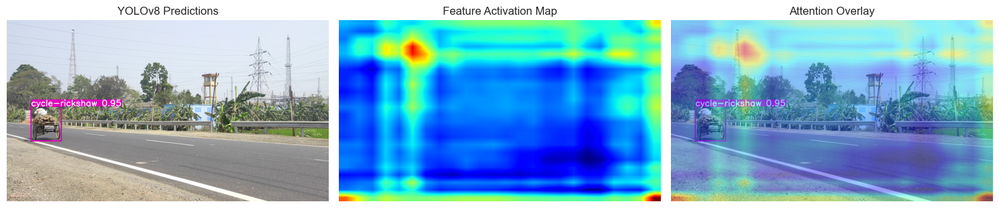

Saved → /content/YOLOv8_IRUVD_Research/xai_outputs/featuremap_xai_000.png


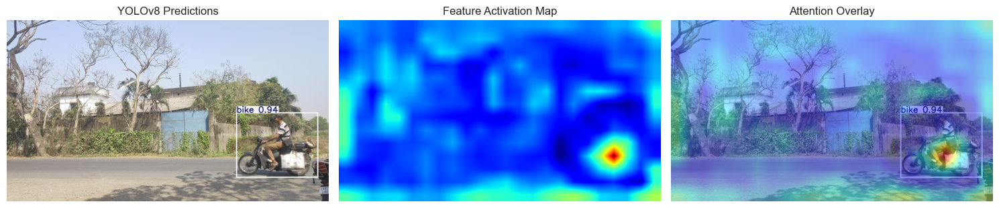

Saved → /content/YOLOv8_IRUVD_Research/xai_outputs/featuremap_xai_001.png


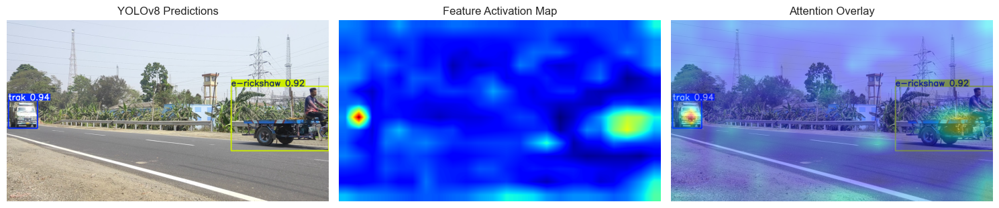

Saved → /content/YOLOv8_IRUVD_Research/xai_outputs/featuremap_xai_002.png


In [ ]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import random

BEST_MODEL_PATH = os.path.join(
    MODELS_DIR,
    'tuned_best_best.pt'
)

if not os.path.exists(BEST_MODEL_PATH):
    BEST_MODEL_PATH = os.path.join(
        MODELS_DIR,
        'best_s.pt'
    )

model = YOLO(BEST_MODEL_PATH)

feature_maps = []

def hook_fn(module, input, output):
    feature_maps.append(output)

target_layer = model.model.model[-2]

hook = target_layer.register_forward_hook(hook_fn)

val_images = glob.glob(
    os.path.join(
        DATASET_ROOT,
        VAL_SPLIT_NAME,
        'images',
        '*.jpg'
    )
)

sample_imgs = random.sample(
    val_images,
    min(3, len(val_images))
)

for i, img_path in enumerate(sample_imgs):

    feature_maps.clear()

    results = model.predict(
        img_path,
        device=DEVICE,
        verbose=False
    )

    pred_img = results[0].plot()

    pred_rgb = cv2.cvtColor(
        pred_img,
        cv2.COLOR_BGR2RGB
    )

    fmap = feature_maps[0]

    fmap = fmap[0].mean(0).detach().cpu().numpy()

    fmap = cv2.resize(
        fmap,
        (pred_rgb.shape[1], pred_rgb.shape[0])
    )

    fmap = (fmap - fmap.min()) / (
        fmap.max() - fmap.min() + 1e-8
    )

    heatmap = cv2.applyColorMap(
        np.uint8(255 * fmap),
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        pred_rgb,
        0.6,
        heatmap,
        0.4,
        0
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(pred_rgb)
    axes[0].set_title('YOLOv8 Predictions')
    axes[0].axis('off')

    axes[1].imshow(fmap, cmap='jet')
    axes[1].set_title('Feature Activation Map')
    axes[1].axis('off')

    axes[2].imshow(overlay)
    axes[2].set_title('Attention Overlay')
    axes[2].axis('off')

    plt.tight_layout()

    save_path = os.path.join(
        XAI_DIR,
        f'featuremap_xai_{i:03d}.png'
    )

    plt.savefig(
        save_path,
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()

    print(f'Saved → {save_path}')

hook.remove()

---
## Section 6: XAI Analysis — Failures, Occlusion, Small Objects, Cluttered Scenes

In [ ]:
def iou(box_a: list, box_b: list) -> float:
    """Compute IoU between two [x1, y1, x2, y2] boxes."""
    xa = max(box_a[0], box_b[0]); ya = max(box_a[1], box_b[1])
    xb = min(box_a[2], box_b[2]); yb = min(box_a[3], box_b[3])
    inter  = max(0, xb - xa) * max(0, yb - ya)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union  = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def categorise_detections(
        model, img_path: str, label_path: str,
        iou_thresh: float = 0.5, small_area_thresh: float = 0.01):
    """Classify GT boxes as TP / FN; predictions as FP."""
    img = cv2.imread(img_path)
    if img is None:
        return {'tp': [], 'fn': [], 'fp': [],
                'has_small': False, 'has_occlusion': False, 'n_objects': 0}
    h, w = img.shape[:2]

    gt_boxes = []
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                cls = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:])
                x1 = int((cx - bw / 2) * w); y1 = int((cy - bh / 2) * h)
                x2 = int((cx + bw / 2) * w); y2 = int((cy + bh / 2) * h)
                gt_boxes.append([x1, y1, x2, y2, cls])

    results    = model.predict(img_path, device=DEVICE, verbose=False, conf=0.25)
    pred_boxes = []
    if results and results[0].boxes is not None:
        for box in results[0].boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
            cls = int(box.cls[0])
            pred_boxes.append([x1, y1, x2, y2, cls])

    matched_pred = set()
    tp_boxes, fn_boxes = [], []
    for gt in gt_boxes:
        best_iou, best_j = 0, -1
        for j, pred in enumerate(pred_boxes):
            if pred[4] == gt[4] and j not in matched_pred:
                v = iou(gt[:4], pred[:4])
                if v > best_iou:
                    best_iou, best_j = v, j
        if best_iou >= iou_thresh:
            tp_boxes.append(gt)
            matched_pred.add(best_j)
        else:
            fn_boxes.append(gt)

    fp_boxes = [pred_boxes[j] for j in range(len(pred_boxes))
                if j not in matched_pred]

    small_flag = any(
        (b[2] - b[0]) * (b[3] - b[1]) / (w * h) < small_area_thresh
        for b in gt_boxes
    )

    occ_flag = False
    for i in range(len(gt_boxes)):
        for j in range(i + 1, len(gt_boxes)):
            if (gt_boxes[i][4] == gt_boxes[j][4] and
                    iou(gt_boxes[i][:4], gt_boxes[j][:4]) > 0.1):
                occ_flag = True

    return {
        'tp': tp_boxes, 'fn': fn_boxes, 'fp': fp_boxes,
        'has_small': small_flag, 'has_occlusion': occ_flag,
        'n_objects': len(gt_boxes),
    }

print('Detection categoriser ready.')

Detection categoriser ready.


Finding failure cases ...
Found 8 images with missed detections.


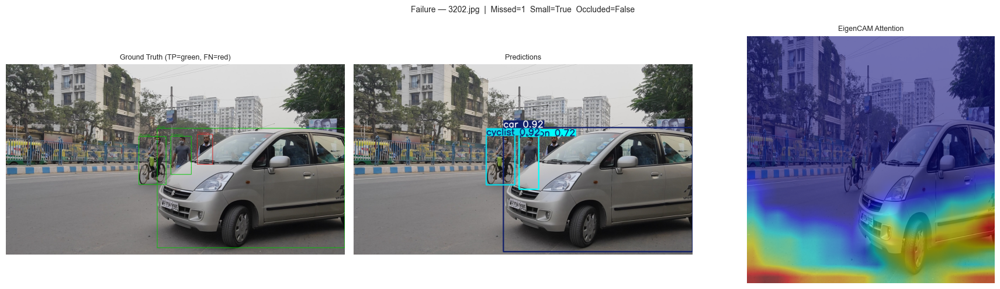

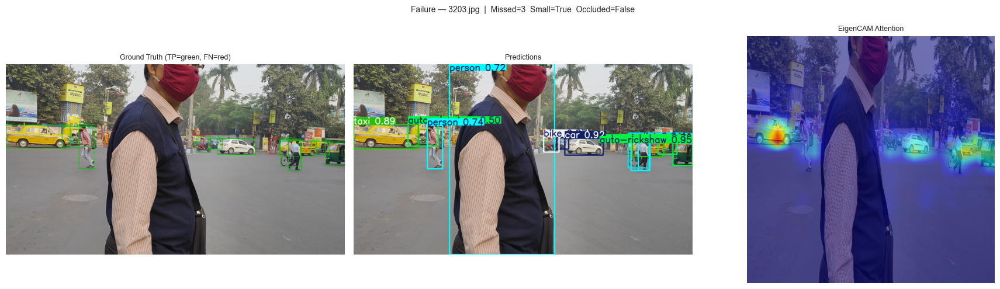

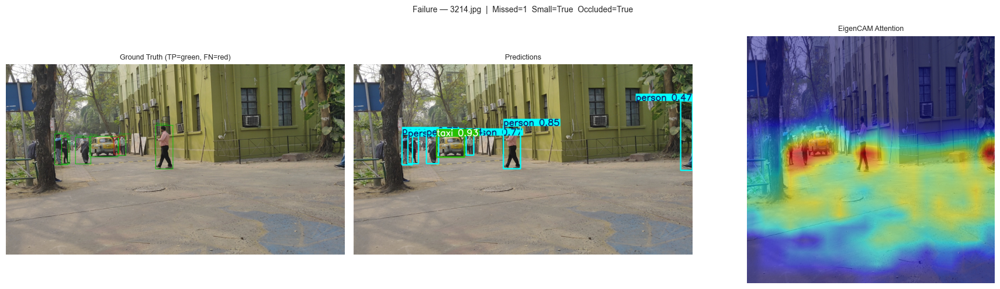

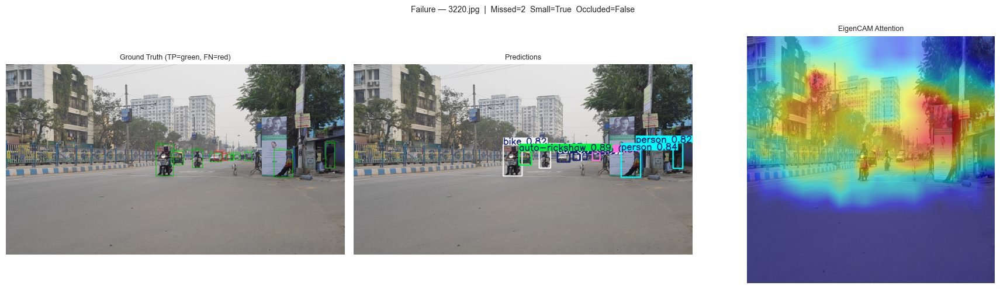

In [ ]:
def find_failure_images(model, val_img_dir, val_lbl_dir, max_cases=10):
    """Find images where the model misses at least one GT object."""
    failures = []
    for img_path in sorted(glob.glob(os.path.join(val_img_dir, '*.jpg'))):
        fname    = Path(img_path).stem
        lbl_path = os.path.join(val_lbl_dir, fname + '.txt')
        if not os.path.exists(lbl_path):
            continue
        cats = categorise_detections(model, img_path, lbl_path)
        if cats['fn']:
            failures.append((img_path, lbl_path, cats))
        if len(failures) >= max_cases:
            break
    return failures


def visualise_failure_with_cam(
        model, img_path, cats, save_dir, prefix='failure'):
    """3-panel: GT (TP=green, FN=red) | Predictions | EigenCAM"""
    img_bgr   = cv2.imread(img_path)
    img_rgb   = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    gt_canvas = img_rgb.copy()

    for box in cats['tp']:
        cv2.rectangle(gt_canvas, (box[0], box[1]), (box[2], box[3]), (0, 200, 0), 2)
        cv2.putText(gt_canvas, f'TP:{CLASS_NAMES[box[4]] if box[4] < len(CLASS_NAMES) else box[4]}',
                    (box[0], max(box[1] - 5, 0)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 200, 0), 1)
    for box in cats['fn']:
        cv2.rectangle(gt_canvas, (box[0], box[1]), (box[2], box[3]), (220, 30, 30), 2)
        cv2.putText(gt_canvas, f'FN:{CLASS_NAMES[box[4]] if box[4] < len(CLASS_NAMES) else box[4]}',
                    (box[0], max(box[1] - 5, 0)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (220, 30, 30), 1)

    pred_bgr = model.predict(img_path, device=DEVICE, verbose=False)[0].plot()
    pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)
    cam_img  = generate_cam(model, img_path, method='eigencam')

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(
        f'Failure — {Path(img_path).name}  |  '
        f'Missed={len(cats["fn"])}  Small={cats["has_small"]}  '
        f'Occluded={cats["has_occlusion"]}',
        fontsize=10, fontweight='bold')

    for ax, img, title in zip(
            axes,
            [gt_canvas, pred_rgb, cam_img],
            ['Ground Truth (TP=green, FN=red)', 'Predictions', 'EigenCAM Attention']):
        ax.imshow(img); ax.set_title(title, fontsize=9); ax.axis('off')

    plt.tight_layout()
    sp = os.path.join(save_dir, f'{prefix}_{Path(img_path).stem}.png')
    plt.savefig(sp, dpi=130, bbox_inches='tight')
    plt.show(); plt.close()
    return sp


val_img_dir = os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'images')
val_lbl_dir = os.path.join(DATASET_ROOT, VAL_SPLIT_NAME, 'labels')
failure_dir = os.path.join(XAI_DIR, 'failure_analysis')
os.makedirs(failure_dir, exist_ok=True)

print('Finding failure cases ...')
failures = find_failure_images(best_model, val_img_dir, val_lbl_dir, max_cases=8)
print(f'Found {len(failures)} images with missed detections.')

for img_path, lbl_path, cats in failures[:4]:
    visualise_failure_with_cam(best_model, img_path, cats, failure_dir)

In [ ]:
def compare_attention_before_after(
        baseline_path: str, tuned_path: str,
        img_path: str, save_dir: str, method: str = 'eigencam'):
    """3-panel: Original | Baseline CAM | Tuned CAM"""
    model_base  = YOLO(baseline_path)
    model_tuned = YOLO(tuned_path)

    cam_base  = generate_cam(model_base,  img_path, method=method)
    cam_tuned = generate_cam(model_tuned, img_path, method=method)

    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_rgb = cv2.resize(img_rgb, (640, 640))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(
        f'Attention Before vs After Tuning ({method.upper()}) — {Path(img_path).name}',
        fontsize=11, fontweight='bold')

    for ax, img, title in zip(
            axes,
            [img_rgb, cam_base, cam_tuned],
            ['Original', f'Baseline ({method.upper()})', f'Tuned ({method.upper()})']):
        ax.imshow(img); ax.set_title(title, fontsize=10); ax.axis('off')

    plt.tight_layout()
    sp = os.path.join(save_dir, f'attention_before_after_{Path(img_path).stem}.png')
    plt.savefig(sp, dpi=130, bbox_inches='tight')
    plt.show(); plt.close()
    return sp


baseline_s_path  = os.path.join(MODELS_DIR, 'yolov8s_baseline_best.pt')
tuned_model_path = os.path.join(MODELS_DIR, 'tuned_best_best.pt')
before_after_dir = os.path.join(XAI_DIR, 'before_after_tuning')
os.makedirs(before_after_dir, exist_ok=True)

if os.path.exists(tuned_model_path) and os.path.exists(baseline_s_path):
    for img in random.sample(val_images, min(4, len(val_images))):
        compare_attention_before_after(
            baseline_s_path, tuned_model_path, img, before_after_dir)
else:
    print('Need both baseline and tuned weights — run Sections 2 & 3 first.')

Need both baseline and tuned weights — run Sections 2 & 3 first.



Challenge: small
  4 images selected.


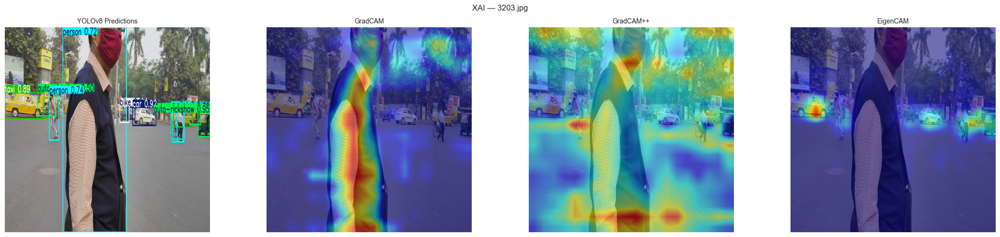

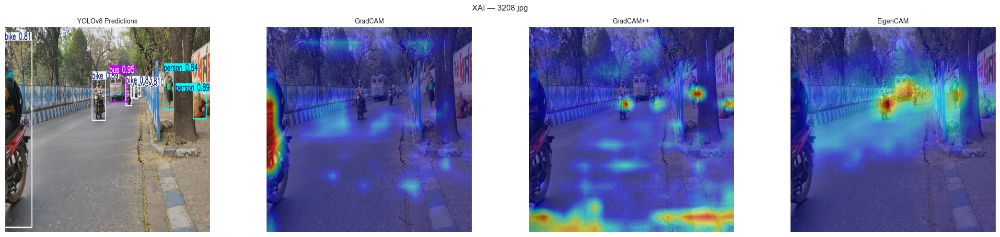


Challenge: cluttered
  4 images selected.


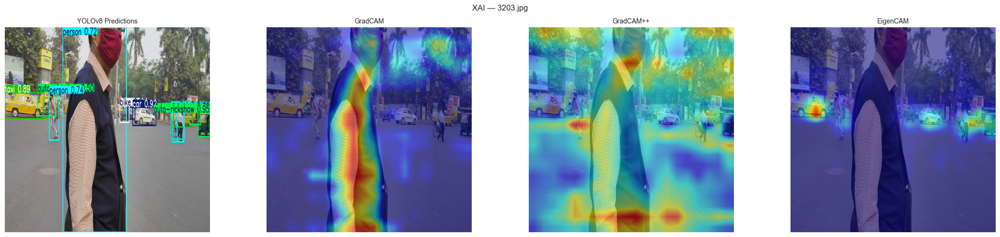

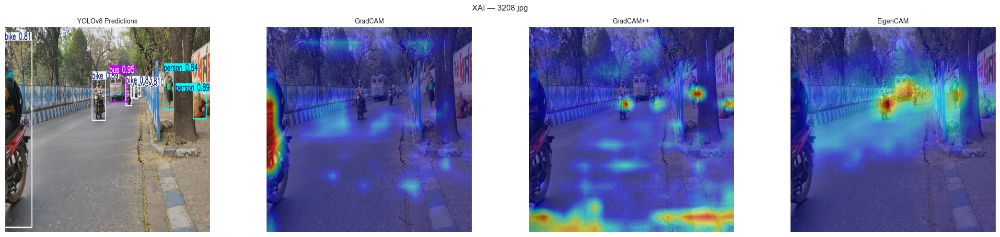


Challenge: occlusion
  4 images selected.


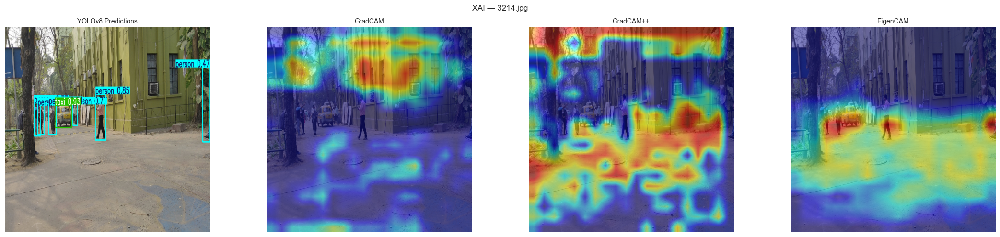

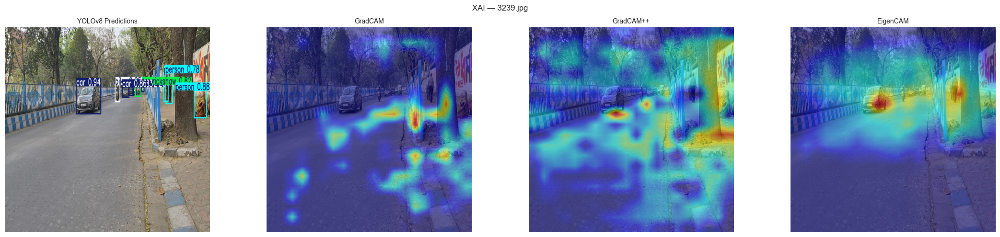

In [ ]:
def select_challenging_images(
        val_img_dir, val_lbl_dir, challenge='small', n=5):
    """
    Select images by challenge type:
      small     : bbox area < 0.005
      cluttered : >= 8 objects
      occlusion : same-class GT boxes with IoU > 0.15
    """
    selected = []
    for img_path in sorted(glob.glob(os.path.join(val_img_dir, '*.jpg'))):
        fname    = Path(img_path).stem
        lbl_path = os.path.join(val_lbl_dir, fname + '.txt')
        if not os.path.exists(lbl_path):
            continue

        with open(lbl_path) as f:
            boxes = [list(map(float, l.split())) for l in f if l.strip()]

        if challenge == 'small':
            if any(b[3] * b[4] < 0.005 for b in boxes if len(b) == 5):
                selected.append(img_path)

        elif challenge == 'cluttered':
            if len(boxes) >= 8:
                selected.append(img_path)

        elif challenge == 'occlusion':
            img = cv2.imread(img_path)
            if img is None:
                continue
            H, W = img.shape[:2]
            px = []
            for b in boxes:
                if len(b) == 5:
                    cx, cy, bw, bh = b[1:]
                    x1 = int((cx - bw / 2) * W); y1 = int((cy - bh / 2) * H)
                    x2 = int((cx + bw / 2) * W); y2 = int((cy + bh / 2) * H)
                    px.append([x1, y1, x2, y2, int(b[0])])
            found = False
            for i in range(len(px)):
                for j in range(i + 1, len(px)):
                    if px[i][4] == px[j][4] and iou(px[i][:4], px[j][:4]) > 0.15:
                        selected.append(img_path)
                        found = True
                        break
                if found:
                    break

        if len(selected) >= n:
            break
    return selected


for challenge in ['small', 'cluttered', 'occlusion']:
    print(f'\nChallenge: {challenge}')
    imgs = select_challenging_images(
        val_img_dir, val_lbl_dir, challenge=challenge, n=4)
    print(f'  {len(imgs)} images selected.')

    ch_dir = os.path.join(XAI_DIR, f'challenge_{challenge}')
    os.makedirs(ch_dir, exist_ok=True)

    for img_path in imgs[:2]:
        save_p = os.path.join(ch_dir, f'{challenge}_{Path(img_path).stem}.png')
        visualise_all_cams(best_model, img_path, save_path=save_p)

---
## Section 7: Plots & Tables

In [ ]:
from datetime import datetime
from tabulate import tabulate
import shutil

def radar_chart(models: dict, metrics: list, save_path: str):

    N = len(metrics)

    angles = np.linspace(
        0,
        2 * np.pi,
        N,
        endpoint=False
    ).tolist()

    angles += angles[:1]

    fig, ax = plt.subplots(
        figsize=(8, 8),
        subplot_kw=dict(polar=True)
    )

    ax.set_theta_offset(np.pi / 2)

    ax.set_theta_direction(-1)

    ax.set_xticks(angles[:-1])

    ax.set_xticklabels(metrics, fontsize=11)

    ax.set_ylim(0, 1)

    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])

    ax.set_yticklabels(
        ['0.2', '0.4', '0.6', '0.8', '1.0'],
        fontsize=7
    )

    ax.grid(
        color='grey',
        linestyle='--',
        linewidth=0.5,
        alpha=0.7
    )

    palette = [
        '#2196F3',
        '#4CAF50',
        '#FF9800',
        '#E91E63'
    ]

    for (label, vals), color in zip(
            models.items(),
            palette):

        data = [
            vals.get(m, 0)
            for m in metrics
        ]

        data += [data[0]]

        ax.plot(
            angles,
            data,
            'o-',
            linewidth=2,
            label=label,
            color=color
        )

        ax.fill(
            angles,
            data,
            alpha=0.10,
            color=color
        )

    ax.set_title(
        'Multi-Metric Model Comparison',
        fontsize=13,
        fontweight='bold',
        pad=20
    )

    ax.legend(
        loc='upper right',
        bbox_to_anchor=(1.35, 1.15),
        fontsize=10
    )

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()

    print(f'Radar chart saved → {save_path}')

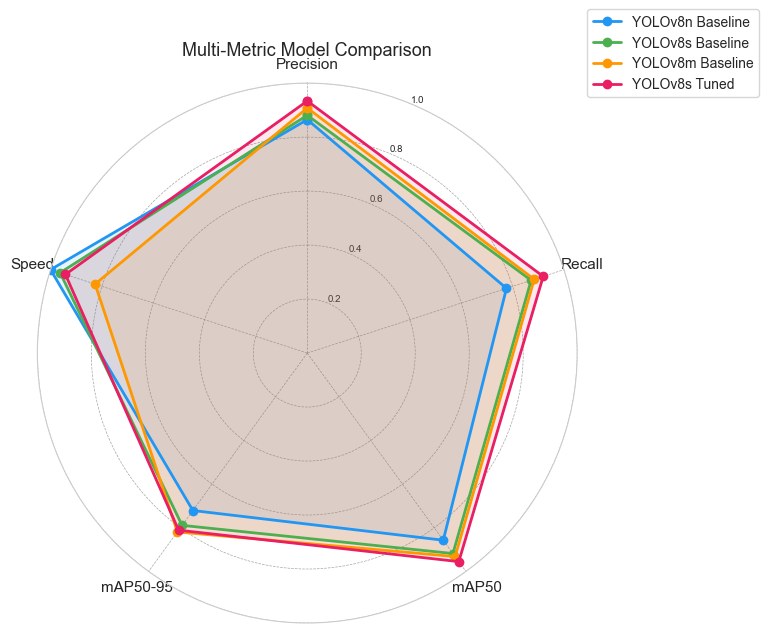

Radar chart saved → /content/YOLOv8_IRUVD_Research/plots/radar_comparison.png


In [ ]:
max_fps = summary_df['FPS'].max()

radar_models = {}

for _, row in summary_df.iterrows():

    radar_models[row['Model']] = {
        'Precision' : row['Precision'],
        'Recall'    : row['Recall'],
        'mAP50'     : row['mAP50'],
        'mAP50-95'  : row['mAP50-95'],
        'Speed'     : row['FPS'] / max_fps,
    }

radar_chart(
    radar_models,
    metrics=[
        'Precision',
        'Recall',
        'mAP50',
        'mAP50-95',
        'Speed'
    ],
    save_path=os.path.join(
        PLOTS_DIR,
        'radar_comparison.png'
    )
)

In [ ]:
def to_latex_table(
        df: pd.DataFrame,
        caption: str,
        label: str):

    return df.to_latex(
        index=False,
        float_format='%.3f',
        caption=caption,
        label=label,
        bold_rows=False,
        escape=True
    )


latex_table = to_latex_table(
    summary_df,
    caption='YOLOv8 Model Comparison',
    label='tab:model_comparison'
)

tables_path = os.path.join(
    RESULTS_DIR,
    'paper_tables.tex'
)

with open(tables_path, 'w') as f:

    f.write(latex_table)

print(f'LaTeX table saved → {tables_path}')

print('\n--- TABLE PREVIEW ---\n')

print(latex_table)

LaTeX table saved → /content/YOLOv8_IRUVD_Research/results/paper_tables.tex

--- TABLE PREVIEW ---

\begin{table}
\caption{YOLOv8 Model Comparison}
\label{tab:model_comparison}
\begin{tabular}{lrrrrr}
\toprule
Model & Precision & Recall & mAP50 & mAP50-95 & FPS \\
\midrule
YOLOv8n Baseline & 0.865 & 0.776 & 0.857 & 0.721 & 24.200 \\
YOLOv8s Baseline & 0.881 & 0.872 & 0.918 & 0.789 & 23.300 \\
YOLOv8m Baseline & 0.908 & 0.884 & 0.932 & 0.819 & 20.000 \\
YOLOv8s Tuned & 0.934 & 0.919 & 0.955 & 0.811 & 22.800 \\
\bottomrule
\end{tabular}
\end{table}



In [ ]:
report_lines = [

    '=' * 70,

    'EXPERIMENT REPORT — YOLOv8 Autonomous Vehicle Detection',

    f'Generated: {datetime.now().strftime("%Y-%m-%d %H:%M")}',

    '=' * 70,

    '',

    '── Dataset ─────────────────────────────────────────────',

    f'Root       : {DATASET_ROOT}',

    f'Classes    : {NUM_CLASSES}',

    '',

    '── Model Comparison ───────────────────────────────────',
]

for _, row in summary_df.iterrows():

    report_lines.append(

        f'{row["Model"]:20s} | '

        f'P={row["Precision"]:.3f}  '

        f'R={row["Recall"]:.3f}  '

        f'mAP50={row["mAP50"]:.3f}  '

        f'mAP50-95={row["mAP50-95"]:.3f}  '

        f'FPS={row["FPS"]}'
    )

report_lines += [

    '',

    '── Output Directories ─────────────────────────────────',

    f'Models  : {MODELS_DIR}',

    f'Results : {RESULTS_DIR}',

    f'Plots   : {PLOTS_DIR}',

    f'XAI     : {XAI_DIR}',

    '=' * 70,
]

report_str = '\n'.join(report_lines)

print('\n')

print(report_str)

report_path = os.path.join(
    PROJECT_ROOT,
    'experiment_report.txt'
)

with open(report_path, 'w') as f:

    f.write(report_str)

print(f'\nExperiment report saved → {report_path}')



EXPERIMENT REPORT — YOLOv8 Autonomous Vehicle Detection
Generated: 2026-05-27 17:31

── Dataset ─────────────────────────────────────────────
Root       : /content/IRUVD/JU_yolov5
Classes    : 14

── Model Comparison ───────────────────────────────────
YOLOv8n Baseline     | P=0.865  R=0.776  mAP50=0.857  mAP50-95=0.721  FPS=24.2
YOLOv8s Baseline     | P=0.881  R=0.872  mAP50=0.918  mAP50-95=0.789  FPS=23.3
YOLOv8m Baseline     | P=0.908  R=0.884  mAP50=0.932  mAP50-95=0.819  FPS=20.0
YOLOv8s Tuned        | P=0.934  R=0.919  mAP50=0.955  mAP50-95=0.811  FPS=22.8

── Output Directories ─────────────────────────────────
Models  : /content/YOLOv8_IRUVD_Research/models
Results : /content/YOLOv8_IRUVD_Research/results
Plots   : /content/YOLOv8_IRUVD_Research/plots
XAI     : /content/YOLOv8_IRUVD_Research/xai_outputs

Experiment report saved → /content/YOLOv8_IRUVD_Research/experiment_report.txt
